In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import netCDF4 as nc
import os

from taia1dvfd.analysis import get_model_variable, met_start_day, read_lotus_temp, mld_sensor, bin_average

In [12]:
# Model files
OUTPUT_FOLDER = '/home/mnex/Desktop/1DV_FD/experiments/3_Lotus_realistic/output/'
CLOSURES = [
    ('k-kl',      r'$k$-$kl$',           'C0'),
    ('k-epsilon', r'$k$-$\varepsilon$',  'C1'),
    ('k-omega',   r'$k$-$\omega$',       'C2'),
    ('gen',       r'gen',                'C3'),
    ('tke',       r'TKE',                'C4'),
    ('kpp',       r'KPP',                'C5'),
]

# Lotus files and params
MET_FILE  = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusmet.epic'
TEMP_FILE = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusnstemp.epic'
N_DAYS    = 160
BIN_HOURS = 6
NENS = 1000

In [13]:
def daily_mean(t, x, n_days):
    day = np.floor(t).astype(int)
    out = np.full(n_days, np.nan)
    for d in range(n_days):
        sel = (day == d) & np.isfinite(x)
        if sel.any():
            out[d] = x[sel].mean()
    return np.arange(n_days) + 0.5, out

# MLD DIagnostic

0 profiles still incomplete after filling


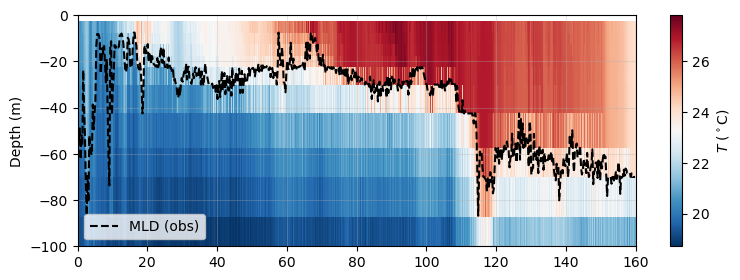

In [14]:
# --- Observations ---
t0 = met_start_day(MET_FILE)
t_obs, depth_s, T_obs = read_lotus_temp(TEMP_FILE, t0, N_DAYS)
mld_obs = mld_sensor(T_obs, depth_s)

edges = np.arange(0.0, N_DAYS + 1e-9, BIN_HOURS / 24)
t_bin = 0.5 * (edges[1:] + edges[:-1])
mld_obs_bin = bin_average(t_obs, mld_obs, edges)

fig, ax = plt.subplots(1, 1, figsize=(9, 3))

pc = ax.pcolormesh(t_obs, -depth_s, T_obs.T, cmap='RdBu_r', shading='nearest')
ax.plot(t_bin, -mld_obs_bin, 'k--', label='MLD (obs)')
ax.set_ylabel('Depth (m)')
ax.set_ylim(-depth_s[-1], 0)
fig.colorbar(pc, ax=ax, label=r'$T$ ($^\circ$C)')
ax.legend(loc='lower left')
ax.grid(alpha=0.3)

In [15]:
def _load(model_name, ne, var, level=None, sign=1, use_daily_mean=False):
    file_name = OUTPUT_FOLDER + f'lotus_stratif_{model_name}_ne{ne}.nc'
    with nc.Dataset(file_name) as data:
        t = data['time'][:] / 86400
        m = data[f'{var}_mean'][:]
        v = data[f'{var}_var'][:]
    if level is not None:
        m, v = m[:, level], v[:, level]
    m = sign * m

    if use_daily_mean:
        t_avg, m = daily_mean(t, m, N_DAYS)
        _,     v = daily_mean(t, v, N_DAYS)
        t = t_avg
    return t, m, v**0.5

def load_MLD(model_name, ne, **kw):
    return _load(model_name, ne, 'mld', sign=-1, **kw)

def load_SST(model_name, ne, **kw):
    return _load(model_name, ne, 'temp', level=0, **kw)

def epic_days(f):
    return f['time'][:].astype(float) + f['time2'][:].astype(float) / 86400e3

In [16]:
def closures_grid(load_fn, t_obs, y_obs, ylabel, title, xlim=(0, 160), ylim=None):
    fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex=True, sharey=True,
                             layout='constrained')

    # Position of the "(a) closure" tag inside each panel
    tx, ha = (0.97, 'right')
    ty, va = (0.95, 'top')

    for i, (ax, (key, label, color)) in enumerate(zip(axes.flat, CLOSURES)):
        
        # Deterministic run
        t, m, s = load_fn(key + '_det', NENS)
        ax.plot(t, m, color=color, lw=1.3, zorder=3, linestyle = '--')
        
        # Stochastic run
        t, m, s = load_fn(key + '_sto', NENS)
        ax.fill_between(t, m - s, m + s, color=color, alpha=0.25, lw=0, zorder=2)
        ax.plot(t, m, color=color, lw=1.3, zorder=3)
        
        # Obs
        ax.plot(t_obs, y_obs, 'k--', lw=1, zorder=4)
        
        ax.text(tx, ty, f'({"abcdef"[i]}) {label}', transform=ax.transAxes, ha=ha, va=va, fontsize=11, color=color, fontweight='bold')
        ax.grid(alpha=0.3)

    axes[0, 0].set_xlim(*xlim)
    if ylim is not None:
        axes[0, 0].set_ylim(*ylim)
    for ax in axes[-1, :]:
        ax.set_xlabel('Time [days]')
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)

    handles = [
        Line2D([], [], color='0.3', lw=1.3,      label='Ensemble mean'),
        Patch(facecolor='0.3', alpha=0.25,        label=r'Ensemble mean $\pm 1\sigma$'),
        Line2D([], [], color='k', ls='--', lw=1,  label='Observations'),
    ]
    fig.legend(handles=handles, loc='outside lower center', ncol=3, frameon=False)
    fig.suptitle(title)
    return fig, axes

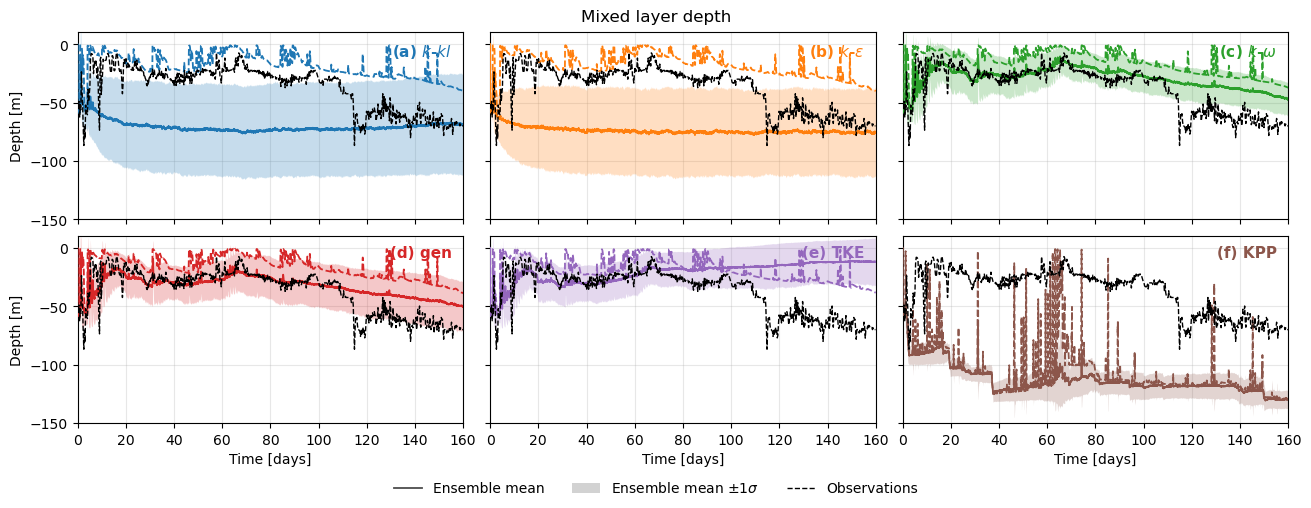

In [17]:
fig_mld, _ = closures_grid(load_MLD, t_bin, -mld_obs_bin,
                           ylabel='Depth [m]', title='Mixed layer depth',
                           ylim=(-150, 10))

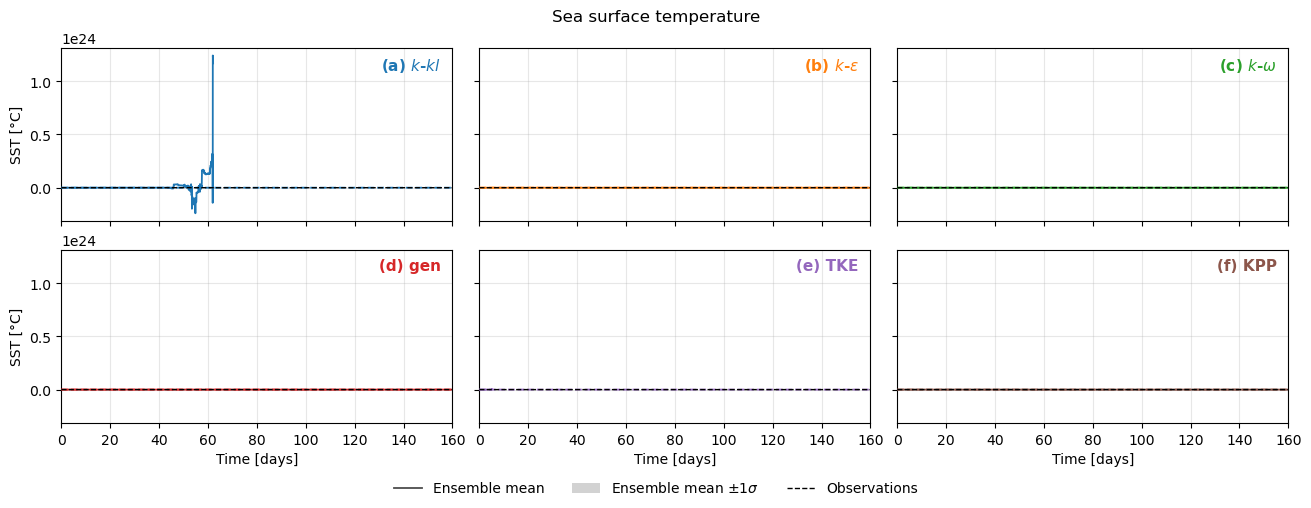

In [ ]:
# ---------- Observed SST ----------
with nc.Dataset(MET_FILE) as f:
    f.set_auto_mask(False)
    t_met = epic_days(f)
    t_met -= t_met[0]
    sst = f['stmp'][:, 0, 0, 0].astype(np.float64)

sst[np.abs(sst) > 1e30] = np.nan
keep = (t_met >= 0) & (t_met <= N_DAYS)
t_met, sst = t_met[keep], sst[keep]
# t_met_d, sst_d = daily_mean(t_met, sst, N_DAYS)

fig_sst, _ = closures_grid(load_SST, t_met, sst, ylabel='SST [°C]', title='Sea surface temperature')

## To explaint the gap after 110 days

In [19]:
# --- Observed Temperature ---
with nc.Dataset(MET_FILE) as f:
    f.set_auto_mask(False)
    t0 = epic_days(f)[0]
    sst = f['stmp'][:, 0, 0, 0]
    
with nc.Dataset(TEMP_FILE) as f:
    f.set_auto_mask(False)
    t_obs = epic_days(f) - t0
    depth = np.abs(f['depth'][:])
    temp  = f['temp'][:, :, 0, 0]

# Depth values
order = np.argsort(depth)
depth, temp = depth[order], temp[:, order]

# Temperature values
temp[np.abs(temp) > 1e30] = np.nan
keep = (t_obs >= 0) & (t_obs <= N_DAYS)
t_obs, temp = t_obs[keep], temp[keep]

In [20]:
# --- Heat content 0-100 m (observations) ---
RHO_CP = 1000.0 * 3985.0
z_int = np.concatenate(([0.0], depth))
T_int = np.concatenate((temp[:, :1], temp), axis=1)
H_obs = RHO_CP * np.trapezoid(T_int, z_int, axis=1)
t_day, H_obs_d = daily_mean(t_obs, H_obs, N_DAYS)
dH_obs = H_obs_d - H_obs_d[0]

# --- Cumulative surface flux from forcing ---
with np.load(os.path.join(OUTPUT_FOLDER, 'lotus_forcing.npz')) as fz:
    Qns, Qsw, dt = fz['Q_ns'], fz['Q_sw'], float(fz['dt'])
Q_net = Qns + Qsw[None, :]
n_f   = Q_net.shape[1]
t_f   = np.arange(n_f + 1) * dt / 86400                              # heat after step k is at (k+1) dt
dH_f  = np.concatenate((np.zeros((Q_net.shape[0], 1)), np.cumsum(Q_net, axis=1) * dt), axis=1)
dH_f_m, dH_f_s = dH_f.mean(0), dH_f.std(0)

GJ = 1e9

# --- Model heat content 0-100 m ---
dH_mod = {}
for (key, label, color) in CLOSURES:
    filepath = OUTPUT_FOLDER + f'lotus_stratif_{key}_ne{NENS}.nc'
    z, t, T_m, _ = get_model_variable(filepath, 'temp')
    z, t, T_m = np.asarray(z).ravel(), np.asarray(t, dtype=float), np.asarray(T_m)
    T_m = T_m.reshape(len(t), -1)
    dz  = np.abs(np.diff(z)).mean()
    sel = np.abs(z) <= 100.0
    dH_mod[key] = (t / 86400, RHO_CP * np.sum(T_m[:, sel] - T_m[0, sel], axis=1) * dz)

# =====================================================================
fig, ax = plt.subplots(2, 1, figsize=(7, 5), sharex=True, constrained_layout=True)

def plot_flux(a):
    a.plot(t_f, dH_f_m / GJ, 'C3', lw=1.5, label=r'$\int (Q_{sw}+Q_{ns})\,dt$')
    a.fill_between(t_f, (dH_f_m - dH_f_s) / GJ, (dH_f_m + dH_f_s) / GJ, color='C3', alpha=0.3, lw=0)

# (a) Observations vs surface flux
plot_flux(ax[0])
ax[0].plot(t_day, dH_obs / GJ, 'k', label=r'$\Delta H$ observed')
ax[0].set_ylabel(r'$\Delta H$ (GJ m$^{-2}$)')
ax[0].legend(loc='lower right', ncol=2)
ax[0].grid(alpha = 0.3)

# (c) Model residual: heat content minus integrated flux
for (key, label, color) in CLOSURES:
    tk, dH = dH_mod[key]
    ax[1].plot(tk, (dH - np.interp(tk, t_f, dH_f_m)) / GJ, color=color, label=label)
ax[1].axhline(0, color='k')
ax[1].set_ylabel(r'$\Delta H - \int Q\,dt$ (GJ m$^{-2}$)')
ax[1].set_xlabel('Time (days since 13 May 1982)')
ax[1].legend(loc='lower left', ncol=2)
ax[1].set_ylim(-0.35, 0.0)

for a, letter in zip(ax, 'ab'):
    a.grid(alpha=0.3)
    a.set_xlim(0, N_DAYS)
    a.text(0.01, 0.95, f'({letter})', transform=a.transAxes, va='top', fontweight='bold')

FileNotFoundError: [Errno 2] No such file or directory: '/home/mnex/Desktop/1DV_FD/experiments/3_Lotus_realistic/output/lotus_stratif_k-kl_ne1000.nc'